In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import numpy as np

In [ ]:
cifar100 = tf.keras.datasets.cifar100
(x_train, y_train), (x_test, y_test) = cifar100.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

In [ ]:
# dataset_dir = "/content/drive/MyDrive/datasets/cifar-100"

# if not os.path.exists(dataset_dir):
#     os.makedirs(dataset_dir, exist_ok=True)

#     (x_train, y_train), (x_test, y_test) = (
#         tf.keras.datasets.cifar100.load_data()
#     )

#     import numpy as np

#     np.savez_compressed(
#         os.path.join(dataset_dir, "cifar100.npz"),
#         x_train=x_train,
#         y_train=y_train,
#         x_test=x_test,
#         y_test=y_test
#     )

In [ ]:
data = np.load(
    "/content/drive/MyDrive/datasets/cifar-100/cifar100.npz"
)

x_train = data["x_train"]
y_train = data["y_train"]
x_test = data["x_test"]
y_test = data["y_test"]
x_train, x_test = x_train / 255.0, x_test / 255.0

In [ ]:
#ML
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(100, activation='softmax')
])

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
history_ml = model.fit(x_train, y_train, epochs=50,validation_split=0.2)

In [ ]:
model.evaluate(x_test,  y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1791 - loss: 3.5234


[3.523391008377075, 0.17910000681877136]

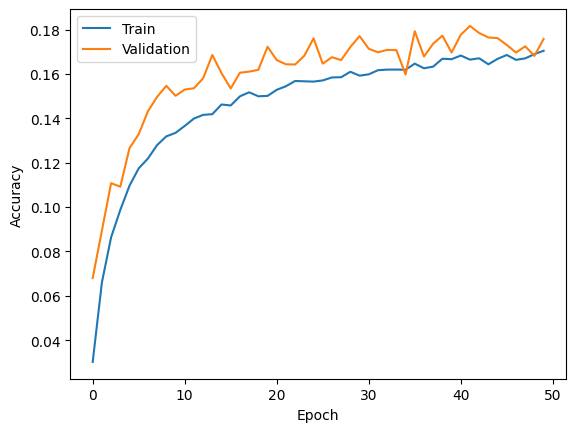

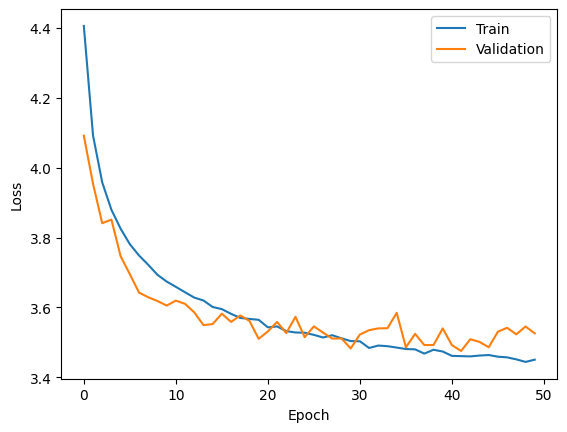

In [ ]:
plt.plot(history_ml.history["accuracy"], label="Train")
plt.plot(history_ml.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
plt.plot(history_ml.history["loss"], label="Train")
plt.plot(history_ml.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [19]:
#DL
model_dl = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(64, (3, 3),activation='relu'),
    tf.keras.layers.Conv2D(64, (3, 3),activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(128, (3, 3),activation='relu'),
    tf.keras.layers.Conv2D(128, (3, 3),activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(256, (3, 3),activation='relu'),
    tf.keras.layers.Conv2D(256, (3, 3),activation='relu'),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(100, activation='softmax')
])

In [20]:
model_dl.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [ ]:
history_dl = model_dl.fit(x_train, y_train, epochs=50,validation_split=0.2)

In [22]:
model_dl.evaluate(x_test,  y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2524 - loss: 5.9520


[5.95198917388916, 0.2524000108242035]

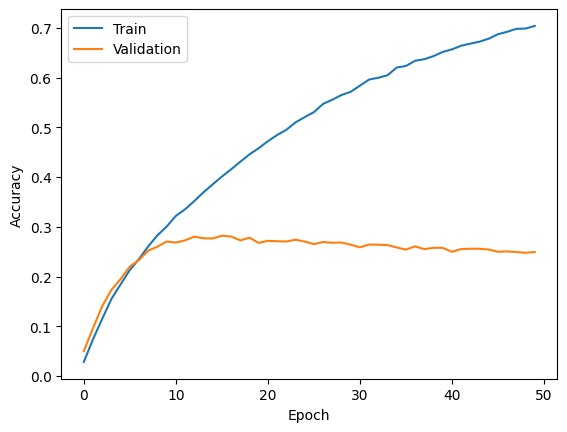

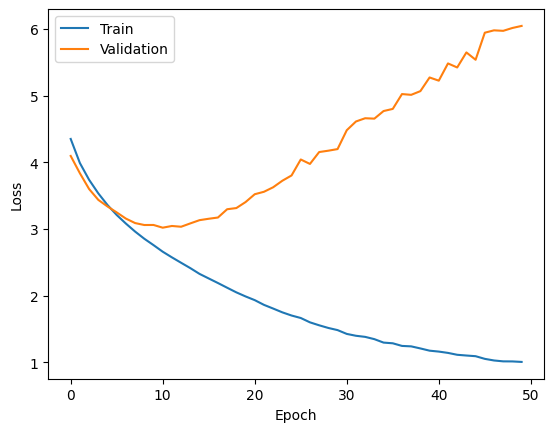

In [23]:
plt.plot(history_dl.history["accuracy"], label="Train")
plt.plot(history_dl.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
plt.plot(history_dl.history["loss"], label="Train")
plt.plot(history_dl.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()